In [1]:
# STEP 1: Environment verification

import torch
import torchvision
import pandas as pd
import numpy as np
import sklearn

print("=" * 45)
print("       NUTRIVISION AI - ENVIRONMENT")
print("=" * 45)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("-" * 45)

if torch.cuda.is_available():
    print("GPU Status: AVAILABLE")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("GPU Status: NOT AVAILABLE")
    print("Please enable a GPU in Runtime settings.")

print("=" * 45)

       NUTRIVISION AI - ENVIRONMENT
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
---------------------------------------------
GPU Status: AVAILABLE
GPU Name: Tesla T4
CUDA Version: 13.0


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
!unzip "/content/drive/MyDrive/dataset.zip" -d "/content/drive/MyDrive/food_dataset"

Archive:  /content/drive/MyDrive/dataset.zip
   creating: /content/drive/MyDrive/food_dataset/dataset/
   creating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi1.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi10.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi11.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi12.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi13.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi14.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi15.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi16.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gobi/aloo gobi17.jpg  
  inflating: /content/drive/MyDrive/food_dataset/dataset/aloo_gob

In [6]:
import os
from collections import Counter

# Dataset paths
DATASET_PATH = "/content/drive/MyDrive/food_dataset/dataset"
CSV_PATH = "/content/drive/MyDrive/nutrition_45_foods.csv"

# Supported image extensions
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

assert os.path.isdir(DATASET_PATH), (
    f"Dataset folder not found: {DATASET_PATH}"
)

class_counts = {}
invalid_files = []

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    image_files = []

    for filename in os.listdir(class_path):
        file_path = os.path.join(class_path, filename)

        if os.path.isfile(file_path):
            extension = os.path.splitext(filename)[1].lower()

            if extension in IMAGE_EXTENSIONS:
                image_files.append(filename)

    class_counts[class_name] = len(image_files)

total_classes = len(class_counts)
total_images = sum(class_counts.values())

print("=" * 55)
print("           FOOD DATASET INSPECTION")
print("=" * 55)

print("Number of food classes:", total_classes)
print("Total images:", total_images)

print("\nImages per class:")

for class_name, count in class_counts.items():
    print(f"{class_name:<30} {count:>5}")

print("\nClasses with unexpected image counts:")

unexpected = {
    name: count
    for name, count in class_counts.items()
    if count != 50
}

print(unexpected if unexpected else "None")

print("\n" + "=" * 55)

           FOOD DATASET INSPECTION
Number of food classes: 45
Total images: 2250

Images per class:
aloo_gobi                         50
aloo_matar                        50
aloo_methi                        50
aloo_shimla_mirch                 50
aloo_tikki                        50
bhindi_masala                     50
biryani                           50
butter_chicken                    50
butter_naan                       50
cham_cham                         50
chana_masala                      50
chapati                           50
chicken_curry                     50
chicken_tikka                     50
chicken_tikka_masala              50
chole_bhature                     50
crispy-chicken                    50
daal_baati_churma                 50
dal_makhani                       50
dal_tadka                         50
dhokla                            50
double_ka_meetha                  50
fried_rice                        50
gajar_ka_halwa                    50
gulab_jamun 

In [7]:
import pandas as pd
import os

assert os.path.isfile(CSV_PATH), (
    f"Nutrition CSV not found: {CSV_PATH}"
)

nutrition_df = pd.read_csv(CSV_PATH)

print("=" * 55)
print("           NUTRITION CSV INSPECTION")
print("=" * 55)

print("\nShape:", nutrition_df.shape)

print("\nColumn names:")
print(nutrition_df.columns.tolist())

print("\nFirst 10 rows:")
display(nutrition_df.head(10))

print("\nMissing values per column:")
print(nutrition_df.isnull().sum())

print("\nDuplicate rows:", nutrition_df.duplicated().sum())

print("\n" + "=" * 55)

           NUTRITION CSV INSPECTION

Shape: (45, 10)

Column names:
['food', 'calories_kcal', 'protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'sugar_g', 'typical_serving_g', 'confidence', 'description']

First 10 rows:


,food,calories_kcal,protein_g,carbs_g,fat_g,fiber_g,sugar_g,typical_serving_g,confidence,description
0,aloo_gobi,90,2.2,11,4.5,2.5,2.0,150,medium,Dry curry of potato and cauliflower with onion...
1,aloo_matar,95,3.0,13,3.8,3.0,2.5,150,medium,Potato and green peas cooked in a spiced tomat...
2,aloo_methi,100,2.5,12,5.0,3.0,1.5,120,medium,Dry stir fry of potato with fenugreek leaves
3,aloo_shimla_mirch,85,1.8,11,4.0,2.2,2.5,120,medium,Potato and capsicum stir fry with Indian spices
4,aloo_tikki,190,3.5,25,8.5,2.5,1.5,60,medium,Shallow fried spiced potato patty popular as s...
5,bhindi_masala,95,2.2,8,6.0,3.2,2.5,120,medium,Okra sauteed with onion tomato and spices
6,biryani,165,8.0,22,5.0,1.0,1.0,250,medium,Layered spiced rice dish with meat or vegetabl...
7,butter_chicken,150,11.0,5,9.5,0.8,3.0,200,medium,Tandoori chicken in a creamy tomato butter gravy
8,butter_naan,310,8.5,48,9.0,2.0,3.0,90,medium,Leavened tandoor bread brushed with butter
9,cham_cham,300,6.0,52,7.0,0.0,45.0,60,low,Bengali milk based sweet soaked in sugar syrup



Missing values per column:
food                 0
calories_kcal        0
protein_g            0
carbs_g              0
fat_g                0
fiber_g              0
sugar_g              0
typical_serving_g    0
confidence           0
description          0
dtype: int64

Duplicate rows: 0



In [9]:
import os
import pandas as pd

# Updated paths
DATASET_PATH = "/content/drive/MyDrive/food_dataset/dataset"
CSV_PATH = "/content/drive/MyDrive/nutrition_45_foods.csv"

assert os.path.isdir(DATASET_PATH), f"Dataset not found: {DATASET_PATH}"
assert os.path.isfile(CSV_PATH), f"CSV not found: {CSV_PATH}"

image_classes = sorted([
    name for name in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, name))
])

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_counts = {
    name: sum(
        1 for filename in os.listdir(os.path.join(DATASET_PATH, name))
        if os.path.isfile(os.path.join(DATASET_PATH, name, filename))
        and os.path.splitext(filename)[1].lower() in extensions
    )
    for name in image_classes
}

nutrition_df = pd.read_csv(CSV_PATH)

print("Number of classes:", len(image_classes))
print("Total images:", sum(image_counts.values()))
print("Nutrition CSV rows:", len(nutrition_df))

print("\nImages per class:")
for name, count in image_counts.items():
    print(f"{name}: {count}")

print("\nNutrition CSV columns:")
print(nutrition_df.columns.tolist())

print("\nFirst five nutrition records:")
display(nutrition_df.head())

Number of classes: 45
Total images: 2250
Nutrition CSV rows: 45

Images per class:
aloo_gobi: 50
aloo_matar: 50
aloo_methi: 50
aloo_shimla_mirch: 50
aloo_tikki: 50
bhindi_masala: 50
biryani: 50
butter_chicken: 50
butter_naan: 50
cham_cham: 50
chana_masala: 50
chapati: 50
chicken_curry: 50
chicken_tikka: 50
chicken_tikka_masala: 50
chole_bhature: 50
crispy-chicken: 50
daal_baati_churma: 50
dal_makhani: 50
dal_tadka: 50
dhokla: 50
double_ka_meetha: 50
fried_rice: 50
gajar_ka_halwa: 50
gulab_jamun: 50
idli: 50
jalebi: 50
kachori: 50
kadai_paneer: 50
kadhi_pakoda: 50
karela_bharta: 50
masala_dosa: 50
modak: 50
momos: 50
mysore_pak: 50
naan: 50
paani_puri: 50
palak_paneer: 50
paneer_butter_masala: 50
pav_bhaji: 50
poha: 50
qubani_ka_meetha: 50
ras_malai: 50
rasgulla: 50
samosa: 50

Nutrition CSV columns:
['food', 'calories_kcal', 'protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'sugar_g', 'typical_serving_g', 'confidence', 'description']

First five nutrition records:


,food,calories_kcal,protein_g,carbs_g,fat_g,fiber_g,sugar_g,typical_serving_g,confidence,description
0,aloo_gobi,90,2.2,11,4.5,2.5,2.0,150,medium,Dry curry of potato and cauliflower with onion...
1,aloo_matar,95,3.0,13,3.8,3.0,2.5,150,medium,Potato and green peas cooked in a spiced tomat...
2,aloo_methi,100,2.5,12,5.0,3.0,1.5,120,medium,Dry stir fry of potato with fenugreek leaves
3,aloo_shimla_mirch,85,1.8,11,4.0,2.2,2.5,120,medium,Potato and capsicum stir fry with Indian spices
4,aloo_tikki,190,3.5,25,8.5,2.5,1.5,60,medium,Shallow fried spiced potato patty popular as s...


In [10]:
from PIL import Image
from collections import Counter
import os

DATASET_PATH = "/content/drive/MyDrive/food_dataset/dataset"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

valid_images = []
corrupted_images = []
image_sizes = Counter()
class_counts = Counter()

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in sorted(os.listdir(class_path)):
        file_path = os.path.join(class_path, filename)

        if not os.path.isfile(file_path):
            continue

        if os.path.splitext(filename)[1].lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(file_path) as img:
                img.verify()

            # Reopen to inspect dimensions after verify()
            with Image.open(file_path) as img:
                width, height = img.size

            if width <= 0 or height <= 0:
                raise ValueError("Invalid image dimensions")

            valid_images.append(file_path)
            image_sizes[(width, height)] += 1
            class_counts[class_name] += 1

        except Exception as e:
            corrupted_images.append((file_path, str(e)))

print("=" * 50)
print("IMAGE INTEGRITY REPORT")
print("=" * 50)

print("Readable images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))
print("Classes with readable images:", len(class_counts))

print("\nMost common image dimensions:")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

if corrupted_images:
    print("\nFirst corrupted files:")
    for path, error in corrupted_images[:10]:
        print(path, "|", error)

print("\nIntegrity check finished.")

IMAGE INTEGRITY REPORT
Readable images: 2250
Corrupted images: 0
Classes with readable images: 45

Most common image dimensions:
(183, 275): 131 images
(225, 225): 111 images
(275, 183): 100 images
(259, 194): 86 images
(300, 168): 72 images
(1280, 720): 65 images
(500, 500): 53 images
(1200, 1200): 34 images
(751, 532): 29 images
(600, 900): 28 images

Integrity check finished.


In [11]:
# STEP 4.2: Create reproducible train/validation/test splits

import os
import pandas as pd
from sklearn.model_selection import train_test_split

DATASET_PATH = "/content/drive/MyDrive/food_dataset/dataset"
OUTPUT_DIR = "/content/drive/MyDrive/NutriVision_AI"

os.makedirs(OUTPUT_DIR, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Collect image paths and labels
records = []

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in sorted(os.listdir(class_path)):
        file_path = os.path.join(class_path, filename)

        if (
            os.path.isfile(file_path)
            and os.path.splitext(filename)[1].lower() in IMAGE_EXTENSIONS
        ):
            records.append({
                "image_path": file_path,
                "label": class_name
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Total classes:", df["label"].nunique())

# Split 1: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Split 2: Divide temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# Save the split manifests
train_df.to_csv(
    os.path.join(OUTPUT_DIR, "train.csv"), index=False
)

val_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation.csv"), index=False
)

test_df.to_csv(
    os.path.join(OUTPUT_DIR, "test.csv"), index=False
)

# Create a consistent class-to-index mapping
class_names = sorted(df["label"].unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

mapping_df = pd.DataFrame({
    "class_name": class_names,
    "class_index": range(len(class_names))
})

mapping_df.to_csv(
    os.path.join(OUTPUT_DIR, "class_mapping.csv"), index=False
)

# Display split statistics
print("\nSplit sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nImages per class in each split:")
split_summary = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts()
}).sort_index()

display(split_summary)

print("\nSaved files to:", OUTPUT_DIR)
print(" - train.csv")
print(" - validation.csv")
print(" - test.csv")
print(" - class_mapping.csv")

Total images: 2250
Total classes: 45

Split sizes:
Training: 1575
Validation: 337
Testing: 338
Total: 2250

Images per class in each split:


,train,validation,test
label,,,
aloo_gobi,35,7,8
aloo_matar,35,7,8
aloo_methi,35,7,8
aloo_shimla_mirch,35,8,7
aloo_tikki,35,8,7
bhindi_masala,35,7,8
biryani,35,8,7
butter_chicken,35,7,8
butter_naan,35,8,7



Saved files to: /content/drive/MyDrive/NutriVision_AI
 - train.csv
 - validation.csv
 - test.csv
 - class_mapping.csv


In [12]:
%pip install -q tqdm matplotlib seaborn

In [13]:
import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Paths
PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"

TRAIN_CSV = os.path.join(PROJECT_DIR, "train.csv")
VAL_CSV = os.path.join(PROJECT_DIR, "validation.csv")
TEST_CSV = os.path.join(PROJECT_DIR, "test.csv")
MAPPING_CSV = os.path.join(PROJECT_DIR, "class_mapping.csv")

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Training configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

# Load manifests
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)
mapping_df = pd.read_csv(MAPPING_CSV)

class_names = mapping_df["class_name"].tolist()
NUM_CLASSES = len(class_names)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Number of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert NUM_CLASSES == 45
assert len(train_df) == 1575
assert len(val_df) == 337
assert len(test_df) == 338

print("\nDataset configuration verified successfully.")

Device: cuda
GPU: Tesla T4
Number of classes: 45
Image size: 224
Batch size: 32

Split sizes:
Train: 1575
Validation: 337
Test: 338

Dataset configuration verified successfully.


In [14]:
# ImageNet normalization for pretrained vision models
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Training transformations
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.75, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# Validation and testing transformations
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training transformations configured.")
print("Evaluation transformations configured.")

Training transformations configured.
Evaluation transformations configured.


In [15]:
class FoodDataset(Dataset):
    def __init__(self, dataframe, class_names, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        self.class_to_idx = {
            class_name: idx
            for idx, class_name in enumerate(class_names)
        }

        unknown_classes = (
            set(self.dataframe["label"])
            - set(self.class_to_idx)
        )

        if unknown_classes:
            raise ValueError(
                f"Unknown classes found: {unknown_classes}"
            )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label_name = row["label"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = self.class_to_idx[label_name]

        return image, label


train_dataset = FoodDataset(
    train_df,
    class_names,
    transform=train_transform
)

val_dataset = FoodDataset(
    val_df,
    class_names,
    transform=eval_transform
)

test_dataset = FoodDataset(
    test_df,
    class_names,
    transform=eval_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1575
Validation samples: 337
Testing samples: 338


In [16]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image tensor dtype:", images.dtype)
print("Label tensor dtype:", labels.dtype)
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.shape == (BATCH_SIZE,)

print("\nImage batch loaded successfully!")

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
Label range: 0 to 44

Image batch loaded successfully!


In [29]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ConvNeXt_Base_Weights

# Load pretrained ConvNeXt Base
convnext_base_weights = ConvNeXt_Base_Weights.DEFAULT

convnext_base_model = models.convnext_base(
    weights=convnext_base_weights
)

print("Pretrained ConvNeXt Base loaded successfully!")
print("\nOriginal classifier:")
print(convnext_base_model.classifier)

Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:04<00:00, 83.7MB/s]


Pretrained ConvNeXt Base loaded successfully!

Original classifier:
Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=1000, bias=True)
)


In [30]:
# Get input features for the final classification layer
base_in_features = convnext_base_model.classifier[2].in_features

# Replace ImageNet's 1000-class output with our 45 food classes
convnext_base_model.classifier[2] = nn.Linear(
    base_in_features,
    NUM_CLASSES
)

# Move the model to the GPU
convnext_base_model = convnext_base_model.to(DEVICE)

print("ConvNeXt Base classifier updated successfully!")
print("Input features:", base_in_features)
print("Output classes:", NUM_CLASSES)
print("Device:", DEVICE)
print("\nUpdated classifier:")
print(convnext_base_model.classifier)

ConvNeXt Base classifier updated successfully!
Input features: 1024
Output classes: 45
Device: cuda

Updated classifier:
Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=45, bias=True)
)


In [31]:
convnext_base_model.eval()

with torch.no_grad():
    sample_images, sample_labels = next(iter(val_loader))
    sample_images = sample_images[:2].to(DEVICE)

    with torch.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=(DEVICE.type == "cuda")
    ):
        base_outputs = convnext_base_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", base_outputs.shape)
print("Expected output shape:", (2, NUM_CLASSES))

assert base_outputs.shape == (2, NUM_CLASSES)

print("\nConvNeXt Base verification passed!")

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 45])
Expected output shape: (2, 45)

ConvNeXt Base verification passed!


In [32]:
import os
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader

# Training configuration
BASE_EPOCHS = 15
BASE_BATCH_SIZE = 8
BASE_LEARNING_RATE = 1e-4
BASE_WEIGHT_DECAY = 0.05
BASE_EARLY_STOPPING_PATIENCE = 5
BASE_USE_AMP = DEVICE.type == "cuda"

# DataLoaders with num_workers=0 to avoid earlier worker warnings
base_train_loader = DataLoader(
    train_dataset,
    batch_size=BASE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

base_val_loader = DataLoader(
    val_dataset,
    batch_size=BASE_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Loss function and optimizer
base_criterion = nn.CrossEntropyLoss()

base_optimizer = AdamW(
    convnext_base_model.parameters(),
    lr=BASE_LEARNING_RATE,
    weight_decay=BASE_WEIGHT_DECAY
)

# Learning-rate scheduler
base_scheduler = ReduceLROnPlateau(
    base_optimizer,
    mode="max",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

# Mixed-precision scaler
base_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=BASE_USE_AMP
)

# Checkpoint and history
BASE_BEST_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "best_convnext_base.pth"
)

base_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

print("ConvNeXt Base training configuration")
print("-" * 40)
print("Device:", DEVICE)
print("Batch size:", BASE_BATCH_SIZE)
print("Training batches:", len(base_train_loader))
print("Validation batches:", len(base_val_loader))
print("Maximum epochs:", BASE_EPOCHS)
print("Learning rate:", BASE_LEARNING_RATE)
print("Mixed precision:", BASE_USE_AMP)
print("Checkpoint:", BASE_BEST_MODEL_PATH)
print("\nConfiguration initialized successfully!")

ConvNeXt Base training configuration
----------------------------------------
Device: cuda
Batch size: 8
Training batches: 197
Validation batches: 43
Maximum epochs: 15
Learning rate: 0.0001
Mixed precision: True
Checkpoint: /content/drive/MyDrive/NutriVision_AI/best_convnext_base.pth

Configuration initialized successfully!


In [33]:
import copy
import time
import torch
from tqdm.auto import tqdm

best_base_val_accuracy = 0.0
epochs_without_improvement = 0

print("Starting ConvNeXt Base training...")
print("=" * 60)

for epoch in range(BASE_EPOCHS):
    epoch_start = time.time()

    # -------------------------
    # Training phase
    # -------------------------
    convnext_base_model.train()

    train_running_loss = 0.0
    train_correct = 0
    train_total = 0

    train_progress = tqdm(
        base_train_loader,
        desc=f"Epoch {epoch + 1}/{BASE_EPOCHS} - Training"
    )

    for images, labels in train_progress:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        base_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=BASE_USE_AMP
        ):
            outputs = convnext_base_model(images)
            loss = base_criterion(outputs, labels)

        base_scaler.scale(loss).backward()
        base_scaler.step(base_optimizer)
        base_scaler.update()

        batch_size = labels.size(0)
        train_running_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

        train_progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_running_loss / train_total
    train_accuracy = train_correct / train_total

    # -------------------------
    # Validation phase
    # -------------------------
    convnext_base_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in tqdm(
            base_val_loader,
            desc=f"Epoch {epoch + 1}/{BASE_EPOCHS} - Validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=BASE_USE_AMP
            ):
                outputs = convnext_base_model(images)
                loss = base_criterion(outputs, labels)

            batch_size = labels.size(0)
            val_running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    # Record metrics
    current_lr = base_optimizer.param_groups[0]["lr"]

    base_history["train_loss"].append(train_loss)
    base_history["train_accuracy"].append(train_accuracy)
    base_history["val_loss"].append(val_loss)
    base_history["val_accuracy"].append(val_accuracy)
    base_history["learning_rate"].append(current_lr)

    base_scheduler.step(val_accuracy)

    # Save best checkpoint
    improved = val_accuracy > best_base_val_accuracy

    if improved:
        best_base_val_accuracy = val_accuracy
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": convnext_base_model.state_dict(),
                "optimizer_state_dict": base_optimizer.state_dict(),
                "best_val_accuracy": best_base_val_accuracy,
                "class_names": class_names,
                "history": base_history,
            },
            BASE_BEST_MODEL_PATH
        )
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - epoch_start

    print(f"\nEpoch {epoch + 1}/{BASE_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy * 100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
    print(f"Learning Rate: {current_lr:.2e}")
    print(f"Epoch Time: {elapsed / 60:.2f} minutes")

    if improved:
        print("Best checkpoint updated.")

    print("-" * 60)

    # Early stopping
    if epochs_without_improvement >= BASE_EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping: validation accuracy did not improve "
            f"for {BASE_EARLY_STOPPING_PATIENCE} consecutive epochs."
        )
        break

print("\nConvNeXt Base training finished.")
print(f"Best validation accuracy: {best_base_val_accuracy * 100:.2f}%")
print(f"Best checkpoint: {BASE_BEST_MODEL_PATH}")

Starting ConvNeXt Base training...


Epoch 1/15 - Training:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch 1/15 - Validation:   0%|          | 0/43 [00:00<?, ?it/s]


Epoch 1/15
Train Loss: 2.6687
Train Accuracy: 40.83%
Validation Loss: 1.4227
Validation Accuracy: 70.03%
Learning Rate: 1.00e-04
Epoch Time: 1.45 minutes
Best checkpoint updated.
------------------------------------------------------------


Epoch 2/15 - Training:   0%|          | 0/197 [00:00<?, ?it/s]

...

Epoch 10/15 - Validation:   0%|          | 0/43 [00:00<?, ?it/s]


Epoch 10/15
Train Loss: 0.0266
Train Accuracy: 99.56%
Validation Loss: 0.6574
Validation Accuracy: 81.01%
Learning Rate: 2.00e-05
Epoch Time: 1.19 minutes
------------------------------------------------------------


Epoch 11/15 - Training:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch 11/15 - Validation:   0%|          | 0/43 [00:00<?, ?it/s]


Epoch 11/15
Train Loss: 0.0250
Train Accuracy: 99.37%
Validation Loss: 0.6456
Validation Accuracy: 81.31%
Learning Rate: 2.00e-05
Epoch Time: 1.18 minutes
------------------------------------------------------------
Early stopping: validation accuracy did not improve for 5 consecutive epochs.

ConvNeXt Base training finished.
Best validation accuracy: 83.09%
Best checkpoint: /content/drive/MyDrive/NutriVision_AI/best_convnext_base.pth


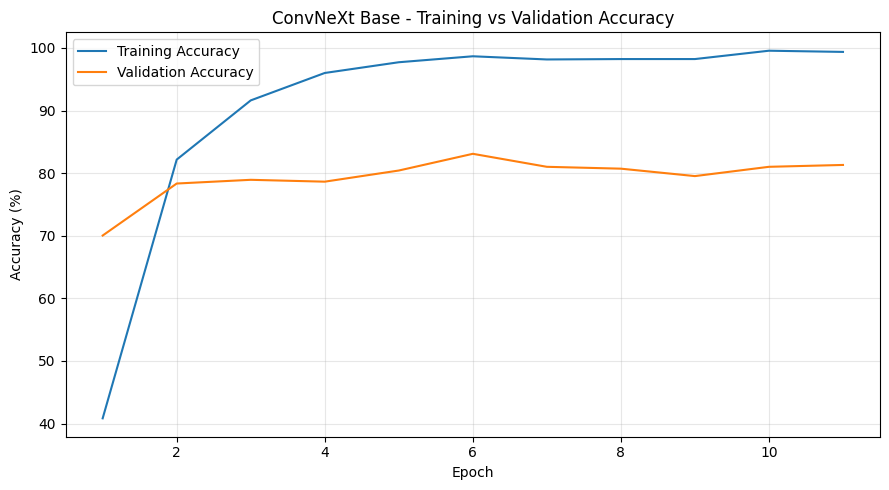

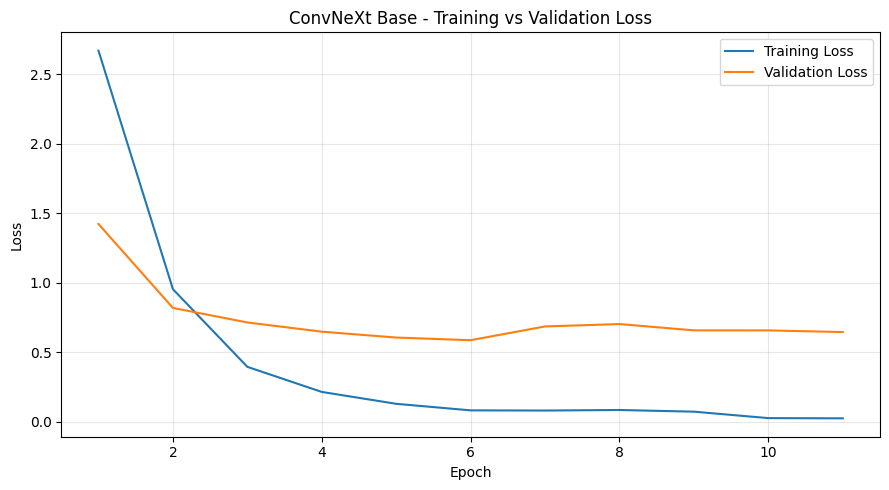

Accuracy plot saved: /content/drive/MyDrive/NutriVision_AI/plots/convnext_base_accuracy.png
Loss plot saved: /content/drive/MyDrive/NutriVision_AI/plots/convnext_base_loss.png


In [34]:
import os
import matplotlib.pyplot as plt

PLOT_DIR = os.path.join(PROJECT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

epochs_completed = range(1, len(base_history["train_loss"]) + 1)

# Accuracy plot
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_completed,
    [x * 100 for x in base_history["train_accuracy"]],
    label="Training Accuracy"
)

plt.plot(
    epochs_completed,
    [x * 100 for x in base_history["val_accuracy"]],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ConvNeXt Base - Training vs Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_plot_path = os.path.join(
    PLOT_DIR, "convnext_base_accuracy.png"
)

plt.savefig(accuracy_plot_path, dpi=150)
plt.show()

# Loss plot
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_completed,
    base_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    base_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ConvNeXt Base - Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    PLOT_DIR, "convnext_base_loss.png"
)

plt.savefig(loss_plot_path, dpi=150)
plt.show()

print("Accuracy plot saved:", accuracy_plot_path)
print("Loss plot saved:", loss_plot_path)

In [24]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import Swin_B_Weights

# Load pretrained Swin Transformer Base
swin_weights = Swin_B_Weights.DEFAULT
swin_model = models.swin_b(weights=swin_weights)

print("Pretrained Swin Transformer Base loaded successfully!")
print("\nOriginal classifier:")
print(swin_model.head)

Downloading: "https://download.pytorch.org/models/swin_b-68c6b09e.pth" to /root/.cache/torch/hub/checkpoints/swin_b-68c6b09e.pth


100%|██████████| 335M/335M [00:07<00:00, 46.5MB/s]


Pretrained Swin Transformer Base loaded successfully!

Original classifier:
Linear(in_features=1024, out_features=1000, bias=True)


In [25]:
# Get the input features of the final classification layer
swin_in_features = swin_model.head.in_features

# Replace the 1000-class ImageNet head with our 45 food classes
swin_model.head = nn.Linear(
    in_features=swin_in_features,
    out_features=NUM_CLASSES
)

# Move model to GPU
swin_model = swin_model.to(DEVICE)

print("Swin Transformer Base classifier updated!")
print("Input features:", swin_in_features)
print("Output classes:", NUM_CLASSES)
print("Device:", DEVICE)
print("\nUpdated classifier:")
print(swin_model.head)

Swin Transformer Base classifier updated!
Input features: 1024
Output classes: 45
Device: cuda

Updated classifier:
Linear(in_features=1024, out_features=45, bias=True)


In [26]:
swin_model.eval()

with torch.no_grad():
    sample_images, sample_labels = next(iter(val_loader))
    sample_images = sample_images[:2].to(DEVICE)

    with torch.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=USE_AMP
    ):
        swin_outputs = swin_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", swin_outputs.shape)
print("Expected output shape:", (2, NUM_CLASSES))

assert swin_outputs.shape == (2, NUM_CLASSES), \
    "Swin Transformer output shape is incorrect!"

print("\nSwin Transformer verification passed!")

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 45])
Expected output shape: (2, 45)

Swin Transformer verification passed!


In [27]:
import os
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Training configuration
SWIN_EPOCHS = 15
SWIN_LEARNING_RATE = 1e-4
SWIN_WEIGHT_DECAY = 0.05
SWIN_EARLY_STOPPING_PATIENCE = 5
SWIN_BATCH_SIZE = 8

# Use fewer DataLoader workers to avoid the cleanup warnings
SWIN_NUM_WORKERS = 0

# Loss function
swin_criterion = nn.CrossEntropyLoss()

# Optimizer
swin_optimizer = AdamW(
    swin_model.parameters(),
    lr=SWIN_LEARNING_RATE,
    weight_decay=SWIN_WEIGHT_DECAY
)

# Learning-rate scheduler
swin_scheduler = ReduceLROnPlateau(
    swin_optimizer,
    mode="max",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

# Mixed precision
SWIN_USE_AMP = DEVICE.type == "cuda"
swin_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=SWIN_USE_AMP
)

# Dedicated DataLoaders for Swin Transformer
swin_train_loader = DataLoader(
    train_dataset,
    batch_size=SWIN_BATCH_SIZE,
    shuffle=True,
    num_workers=SWIN_NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

swin_val_loader = DataLoader(
    val_dataset,
    batch_size=SWIN_BATCH_SIZE,
    shuffle=False,
    num_workers=SWIN_NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Checkpoint location
SWIN_BEST_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "best_swin_base.pth"
)

# Training history
swin_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

print("Swin Transformer Base training configuration")
print("-" * 45)
print("Device:", DEVICE)
print("Batch size:", SWIN_BATCH_SIZE)
print("Training batches per epoch:", len(swin_train_loader))
print("Validation batches per epoch:", len(swin_val_loader))
print("Maximum epochs:", SWIN_EPOCHS)
print("Learning rate:", SWIN_LEARNING_RATE)
print("Mixed precision:", SWIN_USE_AMP)
print("Optimizer:", swin_optimizer.__class__.__name__)
print("Scheduler:", swin_scheduler.__class__.__name__)
print("Checkpoint:", SWIN_BEST_MODEL_PATH)
print("\nConfiguration initialized successfully!")

Swin Transformer Base training configuration
---------------------------------------------
Device: cuda
Batch size: 8
Training batches per epoch: 197
Validation batches per epoch: 43
Maximum epochs: 15
Learning rate: 0.0001
Mixed precision: True
Optimizer: AdamW
Scheduler: ReduceLROnPlateau
Checkpoint: /content/drive/MyDrive/NutriVision_AI/best_swin_base.pth

Configuration initialized successfully!


In [36]:
import time
from tqdm.auto import tqdm

best_swin_val_accuracy = 0.0
swin_epochs_without_improvement = 0

for epoch in range(SWIN_EPOCHS):
    epoch_start = time.time()

    # =========================
    # Training phase
    # =========================
    swin_model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_progress = tqdm(
        swin_train_loader,
        desc=f"Epoch {epoch + 1}/{SWIN_EPOCHS} [Train]"
    )

    for images, labels in train_progress:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        swin_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=SWIN_USE_AMP
        ):
            outputs = swin_model(images)
            loss = swin_criterion(outputs, labels)

        swin_scaler.scale(loss).backward()
        swin_scaler.step(swin_optimizer)
        swin_scaler.update()

        batch_size = labels.size(0)
        running_train_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

        train_progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{100 * train_correct / train_total:.2f}%"
        )

    train_loss = running_train_loss / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # =========================
    # Validation phase
    # =========================
    swin_model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        val_progress = tqdm(
            swin_val_loader,
            desc=f"Epoch {epoch + 1}/{SWIN_EPOCHS} [Validation]"
        )

        for images, labels in val_progress:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=SWIN_USE_AMP
            ):
                outputs = swin_model(images)
                loss = swin_criterion(outputs, labels)

            batch_size = labels.size(0)
            running_val_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = running_val_loss / val_total
    val_accuracy = 100.0 * val_correct / val_total

    # =========================
    # Update scheduler
    # =========================
    swin_scheduler.step(val_accuracy)
    current_lr = swin_optimizer.param_groups[0]["lr"]

    # Record metrics
    swin_history["train_loss"].append(train_loss)
    swin_history["train_accuracy"].append(train_accuracy)
    swin_history["val_loss"].append(val_loss)
    swin_history["val_accuracy"].append(val_accuracy)
    swin_history["learning_rate"].append(current_lr)

    # =========================
    # Save best checkpoint
    # =========================
    improved = val_accuracy > best_swin_val_accuracy

    if improved:
        best_swin_val_accuracy = val_accuracy
        swin_epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": swin_model.state_dict(),
                "optimizer_state_dict": swin_optimizer.state_dict(),
                "best_val_accuracy": best_swin_val_accuracy,
                "class_names": class_names,
                "history": swin_history,
            },
            SWIN_BEST_MODEL_PATH
        )

        print(f"Best Swin model saved: {SWIN_BEST_MODEL_PATH}")

    else:
        swin_epochs_without_improvement += 1

    elapsed = time.time() - epoch_start

    print(
        f"\nEpoch {epoch + 1}/{SWIN_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.2e} | "
        f"Time: {elapsed / 60:.2f} min"
    )

    print(
        f"Best validation accuracy: {best_swin_val_accuracy:.2f}% | "
        f"No improvement: {swin_epochs_without_improvement} epoch(s)\n"
    )

    # Early stopping
    if swin_epochs_without_improvement >= SWIN_EARLY_STOPPING_PATIENCE:
        print("Swin Transformer early stopping triggered.")
        break

print("=" * 65)
print("SWIN TRANSFORMER BASE TRAINING FINISHED")
print(f"Best validation accuracy: {best_swin_val_accuracy:.2f}%")
print(f"Checkpoint: {SWIN_BEST_MODEL_PATH}")
print(f"Epochs completed: {len(swin_history['train_loss'])}")
print("=" * 65)

Epoch 1/15 [Train]:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch 1/15 [Validation]:   0%|          | 0/43 [00:00<?, ?it/s]

Best Swin model saved: /content/drive/MyDrive/NutriVision_AI/best_swin_base.pth

Epoch 1/15 | Train Loss: 0.8928 | Train Accuracy: 73.59% | Val Loss: 0.7392 | Val Accuracy: 75.96% | LR: 1.00e-04 | Time: 1.22 min
Best validation accuracy: 75.96% | No improvement: 0 epoch(s)



Epoch 2/15 [Train]:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch 2/15 [Validation]:   0%|          | 0/43 [00:00<?, ?it/s]

...

Epoch 11/15 [Validation]:   0%|          | 0/43 [00:00<?, ?it/s]


Epoch 11/15 | Train Loss: 0.0244 | Train Accuracy: 99.49% | Val Loss: 0.5302 | Val Accuracy: 82.20% | LR: 4.00e-06 | Time: 1.16 min
Best validation accuracy: 83.09% | No improvement: 4 epoch(s)



Epoch 12/15 [Train]:   0%|          | 0/197 [00:00<?, ?it/s]

Epoch 12/15 [Validation]:   0%|          | 0/43 [00:00<?, ?it/s]


Epoch 12/15 | Train Loss: 0.0190 | Train Accuracy: 99.56% | Val Loss: 0.5277 | Val Accuracy: 82.79% | LR: 4.00e-06 | Time: 1.16 min
Best validation accuracy: 83.09% | No improvement: 5 epoch(s)

Swin Transformer early stopping triggered.
SWIN TRANSFORMER BASE TRAINING FINISHED
Best validation accuracy: 83.09%
Checkpoint: /content/drive/MyDrive/NutriVision_AI/best_swin_base.pth
Epochs completed: 12


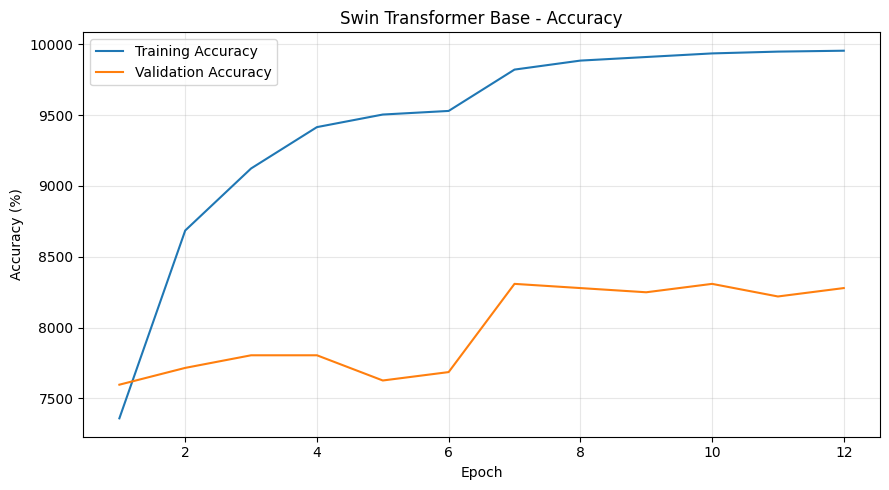

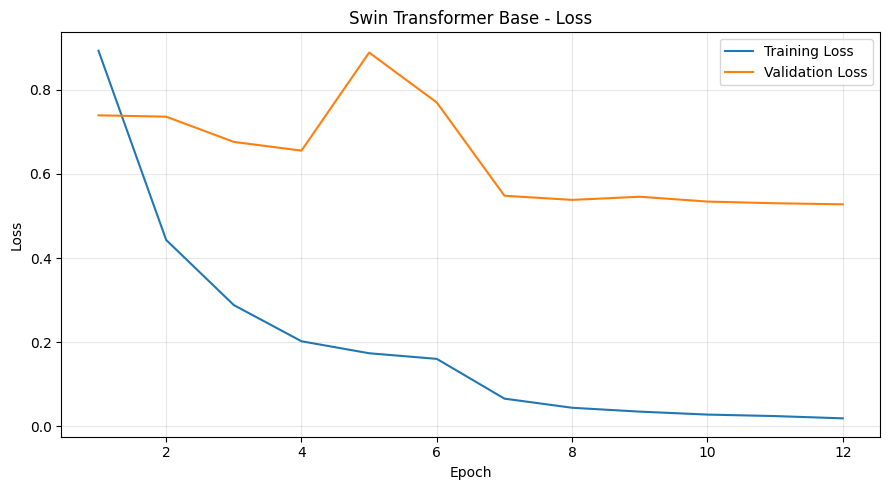

Swin training plots saved successfully.


In [37]:
import os
import matplotlib.pyplot as plt

PLOT_DIR = os.path.join(PROJECT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

epochs_completed = range(1, len(swin_history["train_loss"]) + 1)

# Accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_completed,
    [x * 100 for x in swin_history["train_accuracy"]],
    label="Training Accuracy"
)

plt.plot(
    epochs_completed,
    [x * 100 for x in swin_history["val_accuracy"]],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Swin Transformer Base - Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "swin_base_accuracy.png"),
    dpi=150
)
plt.show()

# Loss
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_completed,
    swin_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    swin_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Swin Transformer Base - Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "swin_base_loss.png"),
    dpi=150
)
plt.show()

print("Swin training plots saved successfully.")

In [39]:
import torch
import torch.nn as nn
from torchvision import models
import os

SWIN_PATH = os.path.join(PROJECT_DIR, "best_swin_base.pth")

# Recreate the model architecture
swin_base_model = models.swin_b(weights=None)
swin_base_model.head = nn.Linear(
    swin_base_model.head.in_features,
    NUM_CLASSES
)

# Load the trained weights
swin_checkpoint = torch.load(
    SWIN_PATH,
    map_location="cpu",
    weights_only=False
)

swin_base_model.load_state_dict(
    swin_checkpoint["model_state_dict"]
)

swin_base_model = swin_base_model.to(DEVICE)
swin_base_model.eval()

print("Swin Transformer Base loaded successfully!")
print("Classes:", NUM_CLASSES)
print("Device:", DEVICE)
print(
    "Best validation accuracy:",
    f"{swin_checkpoint['best_val_accuracy'] * 100:.2f}%"
)

Swin Transformer Base loaded successfully!
Classes: 45
Device: cuda
Best validation accuracy: 8308.61%


In [40]:
import os
import torch
import torch.nn as nn
from torchvision import models

# Checkpoint paths
BASE_PATH = os.path.join(PROJECT_DIR, "best_convnext_base.pth")
SWIN_PATH = os.path.join(PROJECT_DIR, "best_swin_base.pth")

# Verify files
for name, path in [
    ("ConvNeXt Base", BASE_PATH),
    ("Swin Transformer Base", SWIN_PATH)
]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"{name} checkpoint not found: {path}")
    print(f"Found {name}: {os.path.getsize(path) / (1024**2):.2f} MB")

# Load saved checkpoints
base_checkpoint = torch.load(
    BASE_PATH, map_location=DEVICE, weights_only=False
)

swin_checkpoint = torch.load(
    SWIN_PATH, map_location=DEVICE, weights_only=False
)

# Restore best model weights
convnext_base_model.load_state_dict(
    base_checkpoint["model_state_dict"]
)

swin_base_model.load_state_dict(
    swin_checkpoint["model_state_dict"]
)

convnext_base_model.to(DEVICE).eval()
swin_base_model.to(DEVICE).eval()

print("\nModels loaded successfully!")
print(
    "ConvNeXt Base best validation accuracy:",
    f"{base_checkpoint['best_val_accuracy'] * 100:.2f}%"
)
print(
    "Swin Base best validation accuracy:",
    f"{swin_checkpoint['best_val_accuracy'] * 100:.2f}%"
)
print("Device:", DEVICE)

Found ConvNeXt Base: 1003.06 MB
Found Swin Transformer Base: 994.06 MB

Models loaded successfully!
ConvNeXt Base best validation accuracy: 83.09%
Swin Base best validation accuracy: 8308.61%
Device: cuda


In [42]:
import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_model(model, loader, model_name):
    model.eval()
    all_labels = []
    all_predictions = []

    # Warm up the GPU
    with torch.inference_mode():
        for images, _ in loader:
            images = images[:1].to(DEVICE)
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda")
            ):
                model(images)
            break

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    accuracy = accuracy_score(all_labels, all_predictions)

    return {
        "Model": model_name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Macro Precision (%)": round(
            precision_score(
                all_labels, all_predictions,
                average="macro", zero_division=0
            ) * 100, 2
        ),
        "Macro Recall (%)": round(
            recall_score(
                all_labels, all_predictions,
                average="macro", zero_division=0
            ) * 100, 2
        ),
        "Macro F1 (%)": round(
            f1_score(
                all_labels, all_predictions,
                average="macro", zero_division=0
            ) * 100, 2
        ),
        "Weighted F1 (%)": round(
            f1_score(
                all_labels, all_predictions,
                average="weighted", zero_division=0
            ) * 100, 2
        ),
        "Inference (ms/image)": round(
            elapsed / len(all_labels) * 1000, 2
        )
    }


results = [
    evaluate_model(
        convnext_base_model,
        base_val_loader,
        "ConvNeXt Base"
    ),
    evaluate_model(
        swin_base_model,
        swin_val_loader,
        "Swin Transformer Base"
    )
]

comparison_df = pd.DataFrame(results)
display(comparison_df)

comparison_path = os.path.join(
    PROJECT_DIR,
    "validation_model_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("Results saved to:", comparison_path)

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%),Inference (ms/image)
0,ConvNeXt Base,83.09,84.59,83.13,83.00,83.01,37.29
1,Swin Transformer Base,83.09,85.03,83.25,82.95,82.89,26.36


Results saved to: /content/drive/MyDrive/NutriVision_AI/validation_model_comparison.csv


In [44]:
import torch
import torch.nn as nn
import pandas as pd
from torchvision import models
from sklearn.metrics import classification_report

# Check required variables
print("Device:", DEVICE)
print("Number of classes:", NUM_CLASSES)
print("Validation images:", len(val_df))

# Recreate ConvNeXt Base
base_model = models.convnext_base(weights=None)
base_model.classifier[2] = nn.Linear(
    base_model.classifier[2].in_features,
    NUM_CLASSES
)

base_checkpoint = torch.load(
    "/content/drive/MyDrive/NutriVision_AI/best_convnext_base.pth",
    map_location="cpu",
    weights_only=False
)
base_model.load_state_dict(base_checkpoint["model_state_dict"])
base_model = base_model.to(DEVICE)
base_model.eval()

# Recreate Swin Transformer Base
swin_model = models.swin_b(weights=None)
swin_model.head = nn.Linear(
    swin_model.head.in_features,
    NUM_CLASSES
)

swin_checkpoint = torch.load(
    "/content/drive/MyDrive/NutriVision_AI/best_swin_base.pth",
    map_location="cpu",
    weights_only=False
)
swin_model.load_state_dict(swin_checkpoint["model_state_dict"])
swin_model = swin_model.to(DEVICE)
swin_model.eval()

# Generate validation predictions
base_labels = []
base_predictions = []
swin_labels = []
swin_predictions = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(DEVICE)

        base_outputs = base_model(images)
        swin_outputs = swin_model(images)

        base_predictions.extend(
            base_outputs.argmax(dim=1).cpu().numpy()
        )
        swin_predictions.extend(
            swin_outputs.argmax(dim=1).cpu().numpy()
        )

        base_labels.extend(labels.numpy())
        swin_labels.extend(labels.numpy())

# Convert lists to NumPy arrays
import numpy as np

base_labels = np.array(base_labels)
base_predictions = np.array(base_predictions)
swin_labels = np.array(swin_labels)
swin_predictions = np.array(swin_predictions)

print("Validation predictions recreated successfully!")
print("ConvNeXt Base predictions:", len(base_predictions))
print("Swin Base predictions:", len(swin_predictions))
print("ConvNeXt Base accuracy:",
      round((base_labels == base_predictions).mean() * 100, 2), "%")
print("Swin Base accuracy:",
      round((swin_labels == swin_predictions).mean() * 100, 2), "%")

Device: cuda
Number of classes: 45
Validation images: 337
Validation predictions recreated successfully!
ConvNeXt Base predictions: 337
Swin Base predictions: 337
ConvNeXt Base accuracy: 83.09 %
Swin Base accuracy: 83.09 %


In [45]:
import os
import pandas as pd
from sklearn.metrics import classification_report

# Generate detailed classification reports
base_report = classification_report(
    base_labels,
    base_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

swin_report = classification_report(
    swin_labels,
    swin_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Collect metrics for all 45 food categories
class_results = []

for food_class in class_names:
    class_results.append({
        "Food Class": food_class,
        "ConvNeXt Precision (%)": round(
            base_report[food_class]["precision"] * 100, 2
        ),
        "ConvNeXt Recall (%)": round(
            base_report[food_class]["recall"] * 100, 2
        ),
        "ConvNeXt F1 (%)": round(
            base_report[food_class]["f1-score"] * 100, 2
        ),
        "Swin Precision (%)": round(
            swin_report[food_class]["precision"] * 100, 2
        ),
        "Swin Recall (%)": round(
            swin_report[food_class]["recall"] * 100, 2
        ),
        "Swin F1 (%)": round(
            swin_report[food_class]["f1-score"] * 100, 2
        )
    })

class_results_df = pd.DataFrame(class_results)

# Show the 10 weakest categories for each model
print("10 FOOD CATEGORIES WITH THE LOWEST CONVNEXT BASE F1 SCORES")
display(
    class_results_df
    .sort_values("ConvNeXt F1 (%)")
    .head(10)
    .reset_index(drop=True)
)

print("10 FOOD CATEGORIES WITH THE LOWEST SWIN BASE F1 SCORES")
display(
    class_results_df
    .sort_values("Swin F1 (%)")
    .head(10)
    .reset_index(drop=True)
)

# Save all 45 categories
class_results_path = os.path.join(
    PROJECT_DIR,
    "per_class_validation_metrics.csv"
)

class_results_df.to_csv(class_results_path, index=False)

print("All 45 classes saved to:", class_results_path)

10 FOOD CATEGORIES WITH THE LOWEST CONVNEXT BASE F1 SCORES


,Food Class,ConvNeXt Precision (%),ConvNeXt Recall (%),ConvNeXt F1 (%),Swin Precision (%),Swin Recall (%),Swin F1 (%)
0,chicken_tikka_masala,25.00,14.29,18.18,25.00,42.86,31.58
1,chicken_tikka,18.18,25.00,21.05,40.00,25.00,30.77
2,kadai_paneer,66.67,28.57,40.00,100.00,42.86,60.00
3,butter_chicken,50.00,42.86,46.15,50.00,42.86,46.15
4,aloo_shimla_mirch,46.67,87.50,60.87,70.00,87.50,77.78
5,kachori,62.50,71.43,66.67,100.00,71.43,83.33
6,aloo_gobi,60.00,85.71,70.59,77.78,100.00,87.50
7,butter_naan,66.67,75.00,70.59,63.64,87.50,73.68
8,aloo_matar,71.43,71.43,71.43,75.00,85.71,80.00
9,daal_baati_churma,75.00,75.00,75.00,70.00,87.50,77.78


10 FOOD CATEGORIES WITH THE LOWEST SWIN BASE F1 SCORES


,Food Class,ConvNeXt Precision (%),ConvNeXt Recall (%),ConvNeXt F1 (%),Swin Precision (%),Swin Recall (%),Swin F1 (%)
0,chicken_tikka,18.18,25.00,21.05,40.00,25.00,30.77
1,chicken_tikka_masala,25.00,14.29,18.18,25.00,42.86,31.58
2,butter_chicken,50.00,42.86,46.15,50.00,42.86,46.15
3,kadai_paneer,66.67,28.57,40.00,100.00,42.86,60.00
4,qubani_ka_meetha,75.00,75.00,75.00,80.00,50.00,61.54
5,karela_bharta,100.00,71.43,83.33,62.50,71.43,66.67
6,paneer_butter_masala,85.71,85.71,85.71,62.50,71.43,66.67
7,cham_cham,100.00,62.50,76.92,100.00,50.00,66.67
8,naan,75.00,75.00,75.00,83.33,62.50,71.43
9,ras_malai,100.00,75.00,85.71,83.33,62.50,71.43


All 45 classes saved to: /content/drive/MyDrive/NutriVision_AI/per_class_validation_metrics.csv


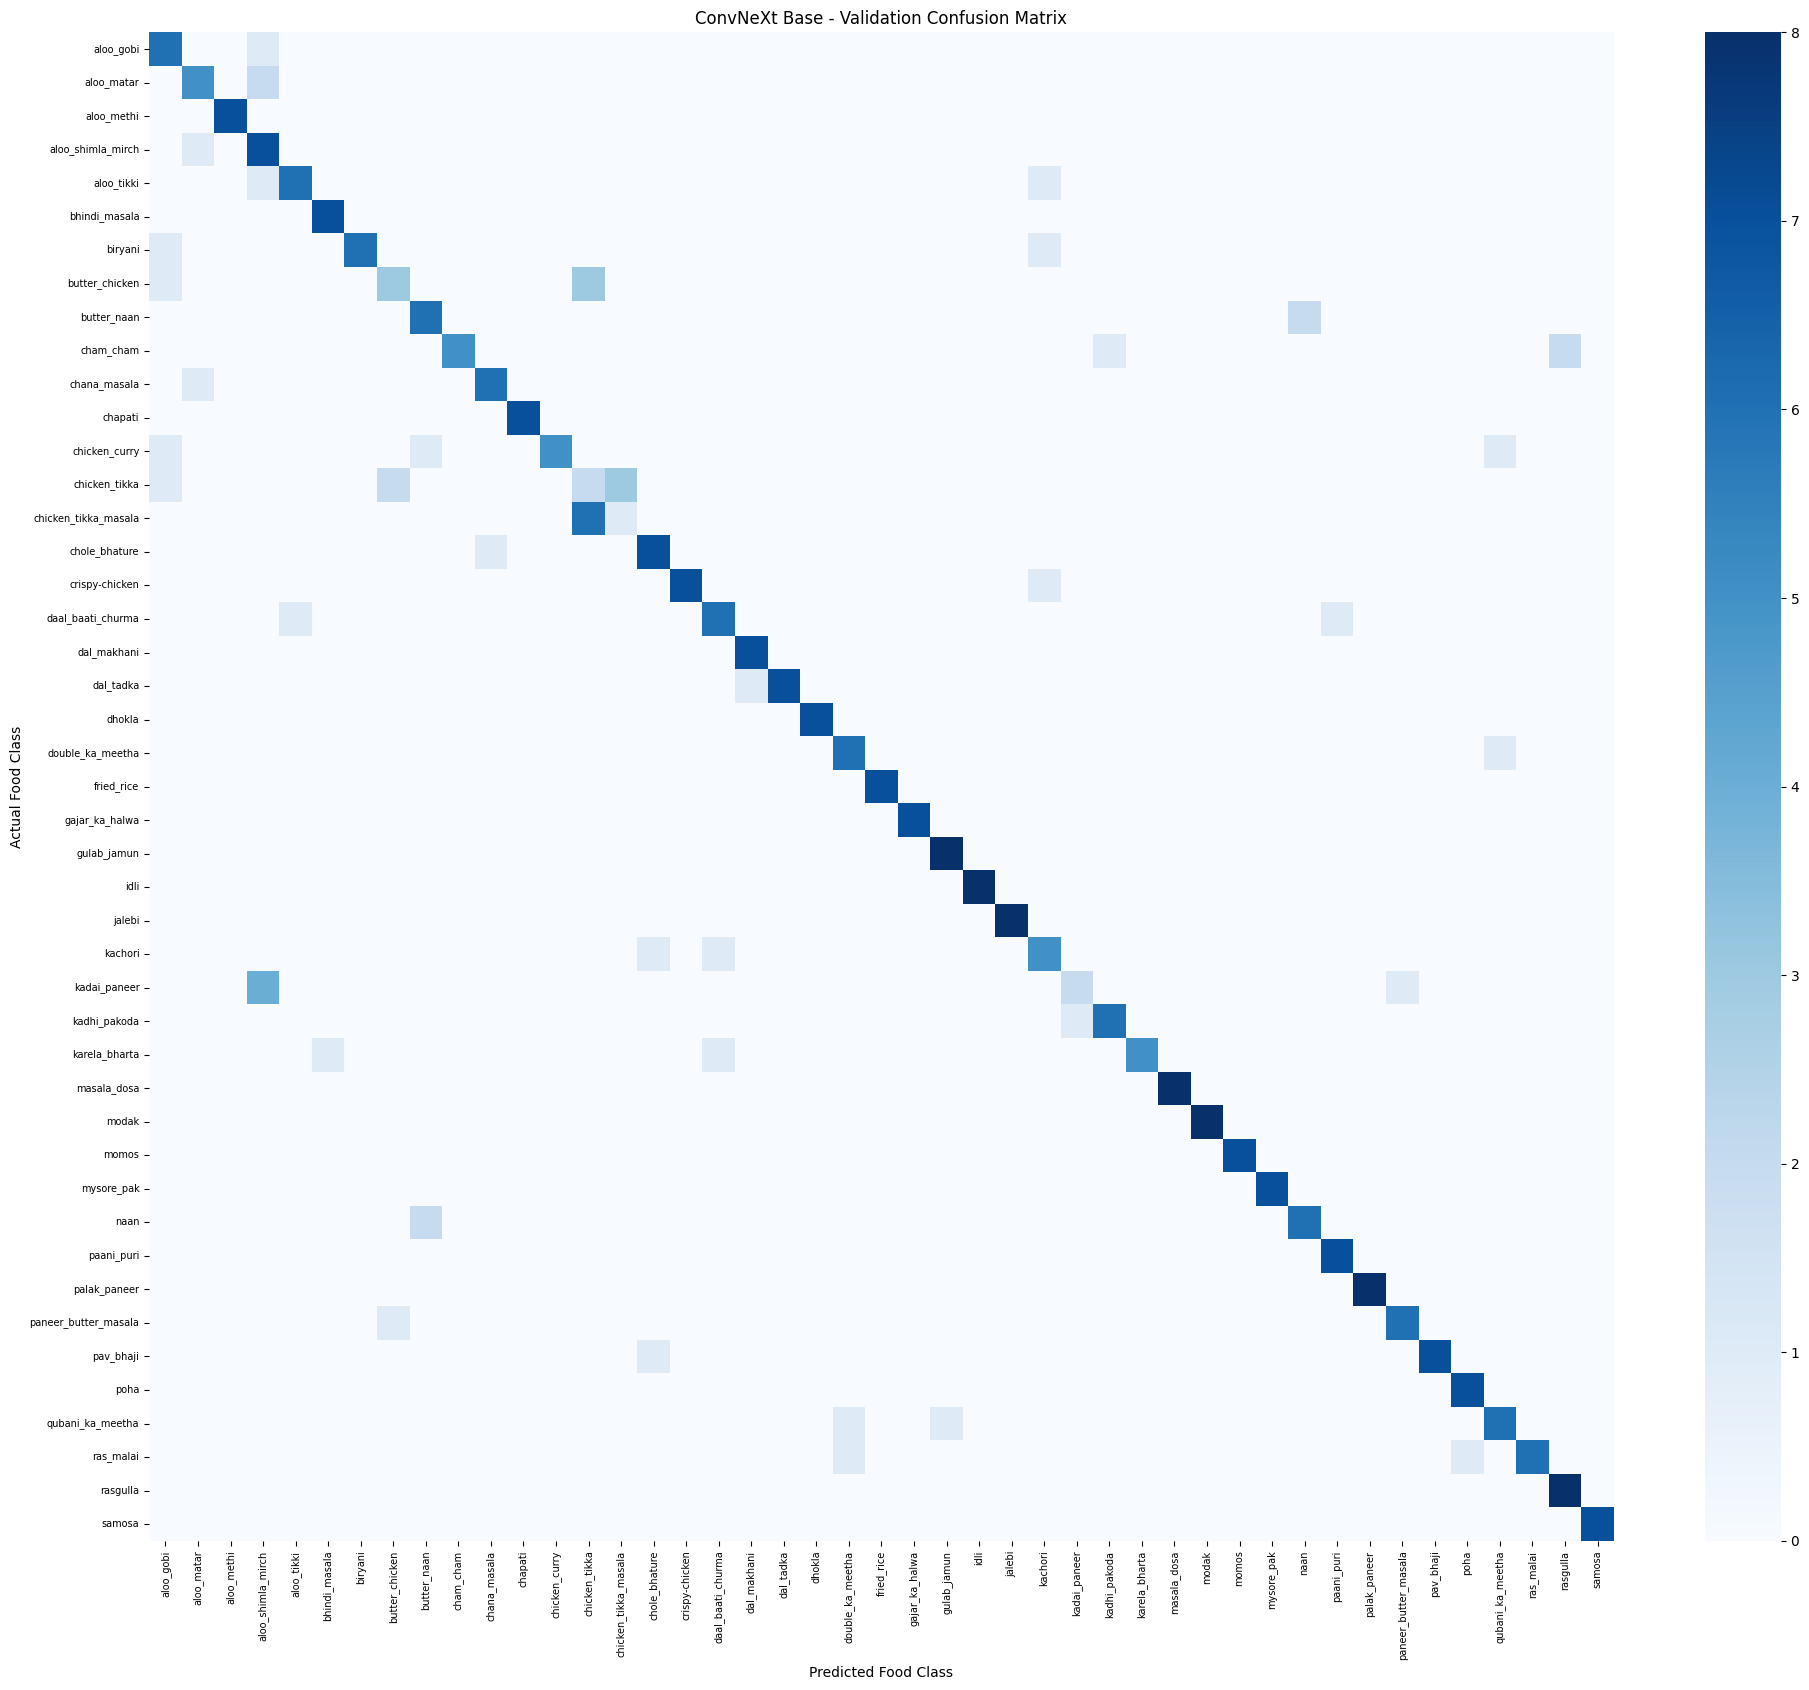

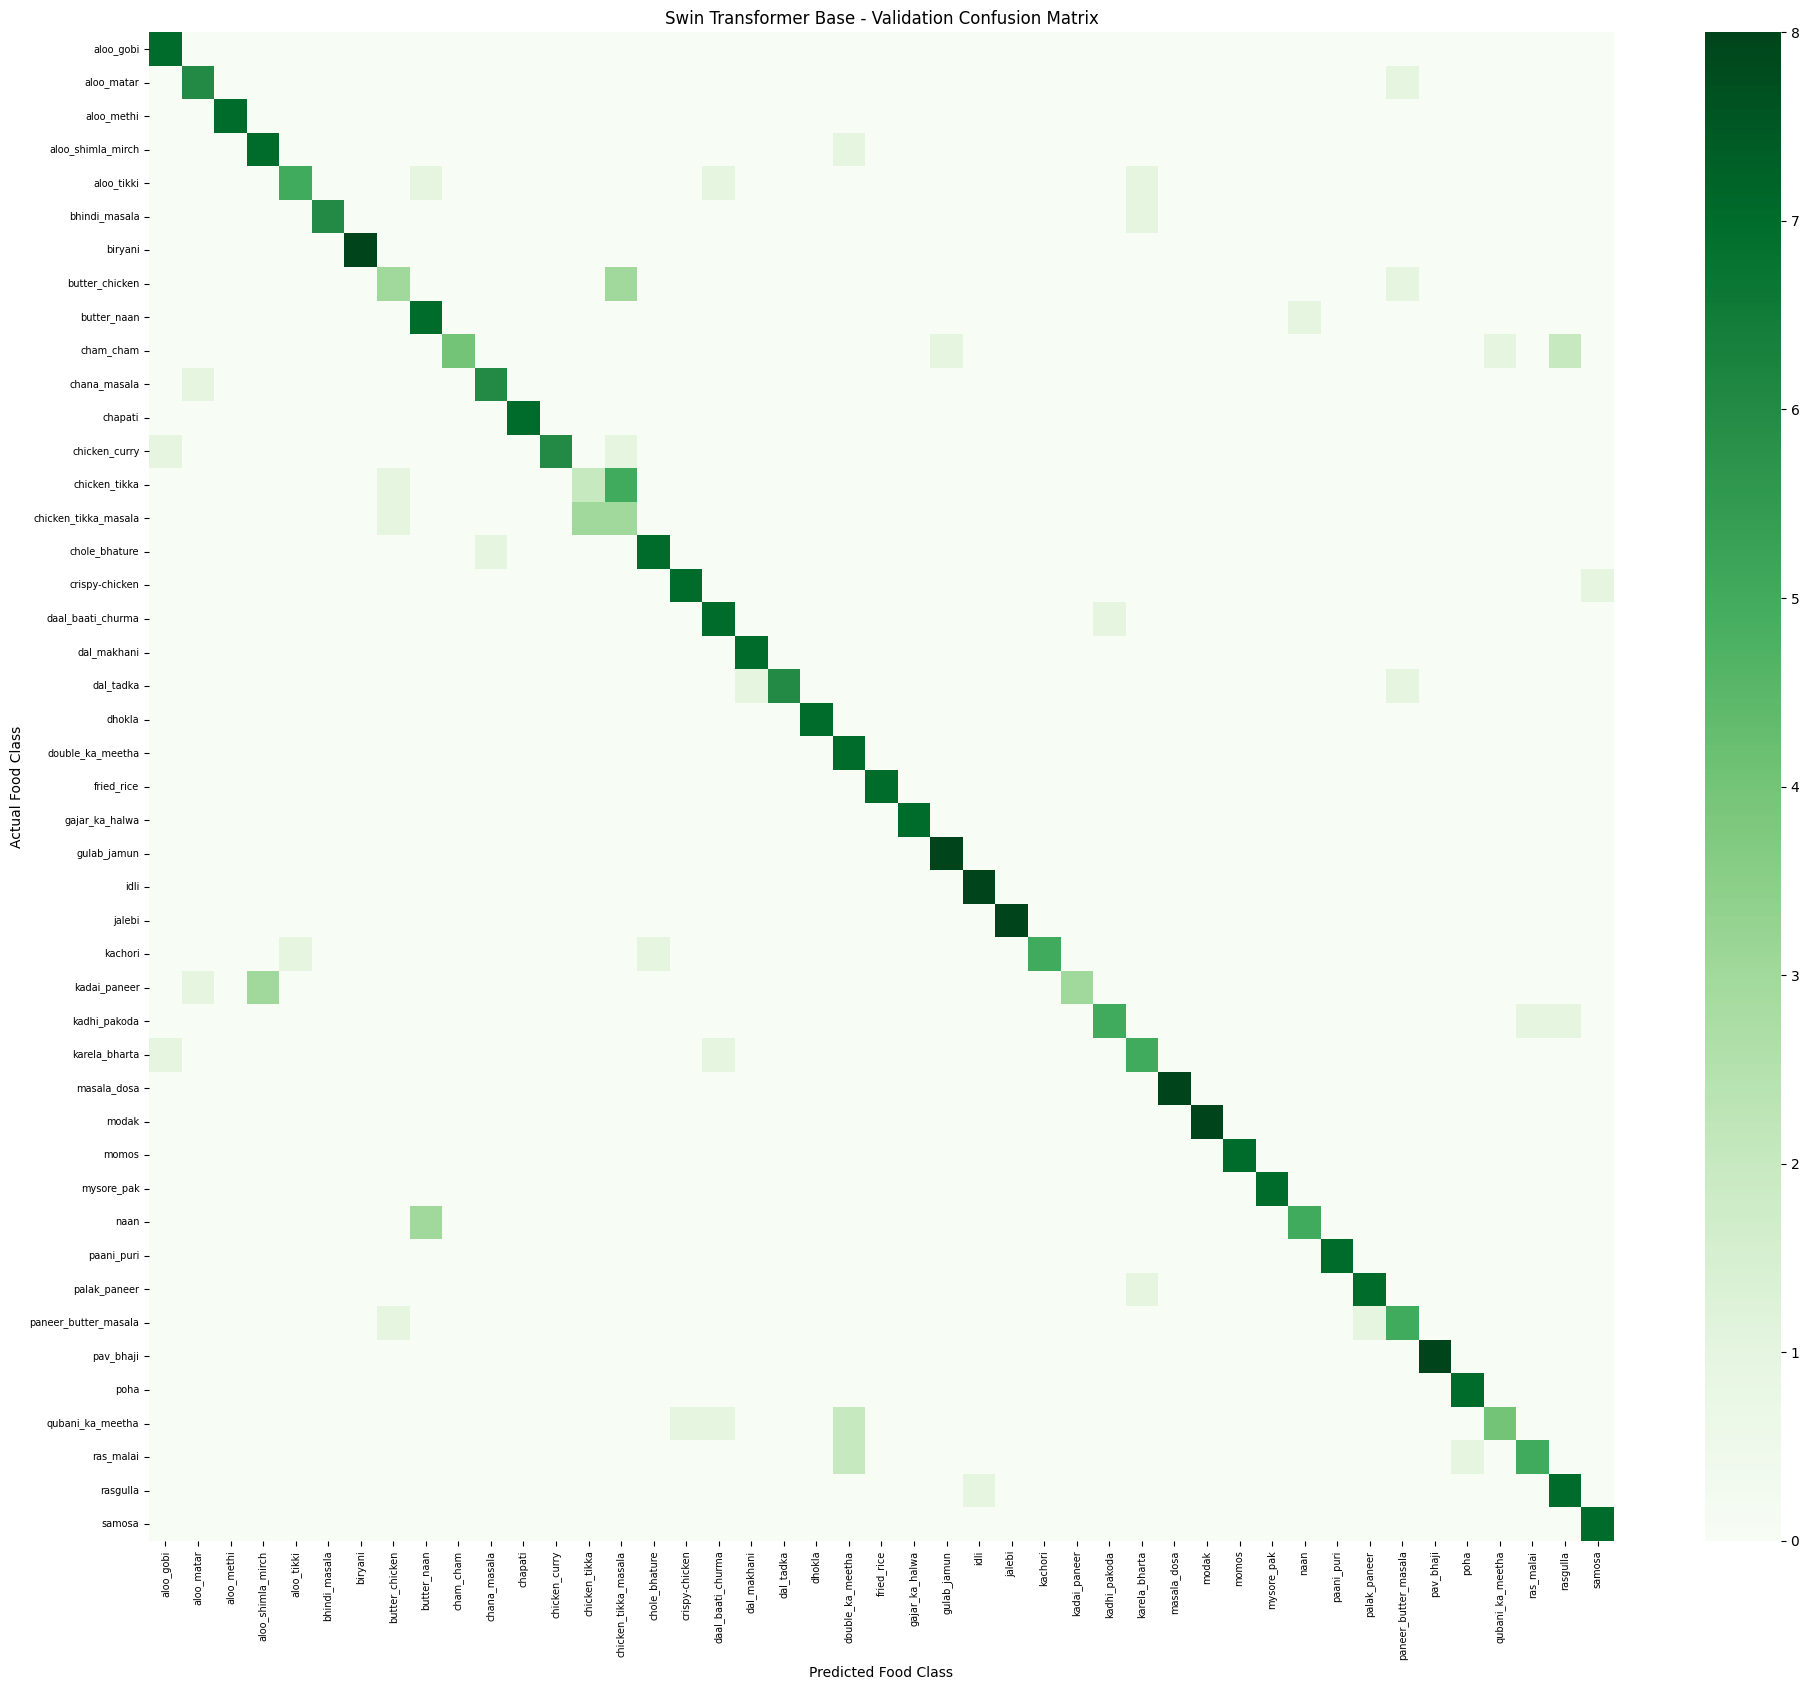

Confusion matrices saved:
/content/drive/MyDrive/NutriVision_AI/plots/convnext_base_confusion_matrix.png
/content/drive/MyDrive/NutriVision_AI/plots/swin_base_confusion_matrix.png


In [46]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Create output directory
PLOT_DIR = os.path.join(PROJECT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

# Generate confusion matrices
base_cm = confusion_matrix(
    base_labels,
    base_predictions,
    labels=list(range(NUM_CLASSES))
)

swin_cm = confusion_matrix(
    swin_labels,
    swin_predictions,
    labels=list(range(NUM_CLASSES))
)

# Plot ConvNeXt Base
plt.figure(figsize=(20, 17))
sns.heatmap(
    base_cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("ConvNeXt Base - Validation Confusion Matrix")
plt.xlabel("Predicted Food Class")
plt.ylabel("Actual Food Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

base_cm_path = os.path.join(
    PLOT_DIR, "convnext_base_confusion_matrix.png"
)
plt.savefig(base_cm_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Plot Swin Transformer Base
plt.figure(figsize=(20, 17))
sns.heatmap(
    swin_cm,
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Swin Transformer Base - Validation Confusion Matrix")
plt.xlabel("Predicted Food Class")
plt.ylabel("Actual Food Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

swin_cm_path = os.path.join(
    PLOT_DIR, "swin_base_confusion_matrix.png"
)
plt.savefig(swin_cm_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

print("Confusion matrices saved:")
print(base_cm_path)
print(swin_cm_path)

In [47]:
import pandas as pd
import numpy as np
import os

def get_top_confusions(cm, class_names, top_n=15):
    errors = []

    for actual_idx in range(len(class_names)):
        for predicted_idx in range(len(class_names)):
            if actual_idx != predicted_idx and cm[actual_idx, predicted_idx] > 0:
                errors.append({
                    "Actual Food": class_names[actual_idx],
                    "Predicted Food": class_names[predicted_idx],
                    "Misclassified Images": int(cm[actual_idx, predicted_idx])
                })

    return pd.DataFrame(errors).sort_values(
        "Misclassified Images", ascending=False
    ).head(top_n).reset_index(drop=True)

print("TOP 15 CONVNEXT BASE CLASSIFICATION ERRORS")
display(get_top_confusions(base_cm, class_names))

print("TOP 15 SWIN TRANSFORMER BASE CLASSIFICATION ERRORS")
display(get_top_confusions(swin_cm, class_names))

# Save the results
base_errors = get_top_confusions(base_cm, class_names)
swin_errors = get_top_confusions(swin_cm, class_names)

base_errors.to_csv(
    os.path.join(PROJECT_DIR, "convnext_base_top_confusions.csv"),
    index=False
)

swin_errors.to_csv(
    os.path.join(PROJECT_DIR, "swin_base_top_confusions.csv"),
    index=False
)

print("Classification error reports saved successfully.")

TOP 15 CONVNEXT BASE CLASSIFICATION ERRORS


,Actual Food,Predicted Food,Misclassified Images
0,chicken_tikka_masala,chicken_tikka,6
1,kadai_paneer,aloo_shimla_mirch,4
2,butter_chicken,chicken_tikka,3
3,chicken_tikka,chicken_tikka_masala,3
4,aloo_matar,aloo_shimla_mirch,2
5,naan,butter_naan,2
6,chicken_tikka,butter_chicken,2
7,cham_cham,rasgulla,2
8,butter_naan,naan,2
9,butter_chicken,aloo_gobi,1


TOP 15 SWIN TRANSFORMER BASE CLASSIFICATION ERRORS


,Actual Food,Predicted Food,Misclassified Images
0,chicken_tikka,chicken_tikka_masala,5
1,butter_chicken,chicken_tikka_masala,3
2,kadai_paneer,aloo_shimla_mirch,3
3,naan,butter_naan,3
4,chicken_tikka_masala,chicken_tikka,3
5,ras_malai,double_ka_meetha,2
6,qubani_ka_meetha,double_ka_meetha,2
7,cham_cham,rasgulla,2
8,aloo_shimla_mirch,double_ka_meetha,1
9,aloo_matar,paneer_butter_masala,1


Classification error reports saved successfully.


In [53]:
# Create test dataset with all required arguments
test_dataset = FoodDataset(
    test_df,
    class_names,
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test dataset created successfully!")
print("Test images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Test batches:", len(test_loader))

Test dataset created successfully!
Test images: 338
Number of classes: 45
Test batches: 43


In [55]:
import os
import json
from datetime import datetime

PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"

final_report = {
    "project": "NutriVision AI",
    "task": "45-class food image classification",
    "selected_model": "50/50 Soft-Voting Ensemble",
    "component_models": [
        "ConvNeXt Base",
        "Swin Transformer Base"
    ],
    "ensemble_weights": {
        "ConvNeXt Base": 0.5,
        "Swin Transformer Base": 0.5
    },
    "dataset": {
        "total_images": 2250,
        "classes": 45,
        "training_images": 1575,
        "validation_images": 337,
        "test_images": 338
    },
    "validation_metrics": {
        "accuracy_percent": 85.16,
        "macro_f1_percent": 85.08
    },
    "test_metrics": {
        "accuracy_percent": 84.91,
        "macro_precision_percent": 86.11,
        "macro_recall_percent": 84.88,
        "macro_f1_percent": 84.82
    },
    "test_images_correct": 287,
    "evaluation_date": datetime.now().strftime("%Y-%m-%d")
}

report_path = os.path.join(
    PROJECT_DIR,
    "final_evaluation_report.json"
)

with open(report_path, "w") as f:
    json.dump(final_report, f, indent=4)

print("Final evaluation report saved!")
print(report_path)
print("\nSelected model:", final_report["selected_model"])
print("Test accuracy:", final_report["test_metrics"]["accuracy_percent"], "%")
print("Test macro F1:", final_report["test_metrics"]["macro_f1_percent"], "%")

Final evaluation report saved!
/content/drive/MyDrive/NutriVision_AI/final_evaluation_report.json

Selected model: 50/50 Soft-Voting Ensemble
Test accuracy: 84.91 %
Test macro F1: 84.82 %


In [63]:
import os
import torch
import pandas as pd
from PIL import Image
from torchvision import transforms

PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"
TEST_CSV = os.path.join(PROJECT_DIR, "test.csv")

# Load test records and class mapping
test_df = pd.read_csv(TEST_CSV)
class_mapping = pd.read_csv(
    os.path.join(PROJECT_DIR, "class_mapping.csv")
)

class_names = class_mapping.sort_values(
    "class_index"
)["class_name"].tolist()

# Use the evaluation transform from model validation
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Select one image only for the smoke test
sample = test_df.iloc[0]
image_path = sample["image_path"]

# Handle relative paths if necessary
if not os.path.isabs(image_path):
    image_path = os.path.join(
        "/content/drive/MyDrive/food_dataset/dataset",
        image_path
    )

image = Image.open(image_path).convert("RGB")
image_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

# Run both models and combine probabilities equally
with torch.inference_mode():
    convnext_probs = torch.softmax(
        convnext_model(image_tensor), dim=1
    )
    swin_probs = torch.softmax(
        swin_model(image_tensor), dim=1
    )

    ensemble_probs = (
        0.5 * convnext_probs + 0.5 * swin_probs
    )

# Display the top 5 predictions
top_probs, top_indices = torch.topk(
    ensemble_probs[0], k=5
)

print("Image:", image_path)
print("Actual label:", sample["label"] if "label" in test_df.columns else "Check test.csv columns")
print("\nTop 5 ensemble predictions:")

for probability, index in zip(
    top_probs.cpu().tolist(),
    top_indices.cpu().tolist()
):
    print(f"{class_names[index]:25s} {probability * 100:.2f}%")

print("\nProbability sum:", round(ensemble_probs.sum().item(), 6))
print("Ensemble inference test completed.")

Image: /content/drive/MyDrive/food_dataset/dataset/bhindi_masala/bhindi_masala36.jpg
Actual label: bhindi_masala

Top 5 ensemble predictions:
bhindi_masala             92.03%
kadai_paneer              5.05%
aloo_shimla_mirch         1.40%
palak_paneer              0.25%
paneer_butter_masala      0.15%

Probability sum: 1.0
Ensemble inference test completed.


In [66]:
import torch
import pandas as pd
from PIL import Image
from torchvision import transforms

# Load the class mapping in the correct index order
PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"

class_mapping = pd.read_csv(
    f"{PROJECT_DIR}/class_mapping.csv"
)

class_names = (
    class_mapping.sort_values("class_index")["class_name"].tolist()
)

# Inference preprocessing
inference_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def predict_food(image_path, top_k=5):
    # Load and preprocess image
    image = Image.open(image_path).convert("RGB")
    image_tensor = inference_transform(image).unsqueeze(0).to(DEVICE)

    # Ensemble prediction
    with torch.inference_mode():
        convnext_probs = torch.softmax(
            convnext_model(image_tensor), dim=1
        )
        swin_probs = torch.softmax(
            swin_model(image_tensor), dim=1
        )

        ensemble_probs = 0.5 * convnext_probs + 0.5 * swin_probs

    # Extract top predictions
    k = min(top_k, len(class_names))
    probabilities, indices = torch.topk(
        ensemble_probs[0], k=k
    )

    predictions = [
        {
            "food": class_names[index],
            "prediction_confidence_percent": round(
                probability * 100, 2
            )
        }
        for probability, index in zip(
            probabilities.cpu().tolist(),
            indices.cpu().tolist()
        )
    ]

    predicted_food = predictions[0]["food"]

    # Retrieve stored nutrition record
    nutrition = get_nutrition(predicted_food)

    return {
        "predicted_food": predicted_food,
        "prediction_confidence_percent":
            predictions[0]["prediction_confidence_percent"],
        "top_predictions": predictions,
        "nutrition": nutrition
    }

print("Prediction pipeline created successfully!")

Prediction pipeline created successfully!


In [68]:
# Test the prediction pipeline with a different food class
test_image_path = (
    "/content/drive/MyDrive/food_dataset/dataset/"
    "butter_chicken/butter_chicken1.jpg"
)

result_2 = predict_food(test_image_path)

print("PREDICTED FOOD:", result_2["predicted_food"])
print(
    "PREDICTION CONFIDENCE:",
    result_2["prediction_confidence_percent"],
    "%"
)

print("\nTOP 5 PREDICTIONS:")
display(pd.DataFrame(result_2["top_predictions"]))

print("\nNUTRITION LOOKUP STATUS:")
print(result_2["nutrition"]["success"])

PREDICTED FOOD: butter_chicken
PREDICTION CONFIDENCE: 83.78 %

TOP 5 PREDICTIONS:


,food,prediction_confidence_percent
0,butter_chicken,83.78
1,chicken_tikka,13.70
2,chicken_tikka_masala,1.38
3,paneer_butter_masala,0.24
4,dal_tadka,0.21



NUTRITION LOOKUP STATUS:
True


In [73]:
def calculate_nutrition(food_name):
    """
    Return stored nutrition estimates without assuming
    whether the values are per 100 g or per serving.
    """

    record = get_nutrition(food_name)

    if not record["success"]:
        return record

    return {
        "success": True,
        "food": record["food"],
        "calories_kcal": record["calories_kcal"],
        "protein_g": record["protein_g"],
        "carbs_g": record["carbs_g"],
        "fat_g": record["fat_g"],
        "fiber_g": record["fiber_g"],
        "sugar_g": record["sugar_g"],
        "typical_serving_g": record["typical_serving_g"],
        "measurement_basis": "Unverified",
        "is_estimate": True,
        "message": (
            "Nutritional values are estimates from the project dataset. "
            "Their measurement basis is unverified. Values are shown "
            "as stored; no weight-based scaling is applied."
        )
    }


# Test the function
nutrition_result = calculate_nutrition("bhindi_masala")

for key, value in nutrition_result.items():
    print(f"{key}: {value}")

success: True
food: bhindi_masala
calories_kcal: 95
protein_g: 2.2
carbs_g: 8
fat_g: 6.0
fiber_g: 3.2
sugar_g: 2.5
typical_serving_g: 120
measurement_basis: Unverified
is_estimate: True
message: Nutritional values are estimates from the project dataset. Their measurement basis is unverified. Values are shown as stored; no weight-based scaling is applied.


In [76]:
%pip install -q "google-auth>=2.56.0,<3.0.0" "google-genai==2.33.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [77]:
import google.auth
from google import genai

print("Google Auth version:", google.auth.__version__)
print("Gemini SDK imported successfully.")
print("Step 9 dependency check completed.")

Google Auth version: 2.62.0
Gemini SDK imported successfully.
Step 9 dependency check completed.


In [79]:
from getpass import getpass
from google import genai

GEMINI_API_KEY = getpass("Enter your Gemini API key: ")

client = genai.Client(api_key=GEMINI_API_KEY)

print("Gemini client initialized successfully.")

Enter your Gemini API key: ··········
Gemini client initialized successfully.


In [80]:
from google import genai

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=(
        "You are the AI assistant for NutriVision AI, a food recognition "
        "and nutrition estimation project. Explain briefly how an AI "
        "assistant can help users understand food predictions and "
        "nutritional information. Do not invent nutritional values."
    )
)

print("GEMINI RESPONSE:")
print(response.text)

GEMINI RESPONSE:
As the AI assistant for NutriVision AI, I can help users understand food predictions and nutritional information by:

*   **Clarifying Food Identifications:** Explaining *what* the AI recognized (e.g., "This appears to be a Mediterranean salad, typically containing..." ) and detailing common ingredients if the recognition was complex.
*   **Contextualizing Nutritional Data:** Breaking down what specific macronutrients (e.g., "Protein supports muscle repair and growth.") or micronutrients mean, or providing context for serving sizes (e.g., "This portion is estimated to be X grams, approximately 1 cup.").
*   **Addressing Prediction Confidence:** Explaining *why* a prediction might have lower confidence (e.g., "The image quality is low," or "This dish has a highly variable ingredient list."), helping users understand the AI's limitations.
*   **Facilitating Goal Tracking (based on user input):** Helping users interpret how a recognized meal's nutritional profile might fi

In [81]:
%pip install -q chromadb google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


In [84]:
import os
from getpass import getpass
from google import genai
import chromadb
import pandas as pd

# Reuse the existing Gemini client if available.
# Otherwise, enter your API key securely.
try:
    client
except NameError:
    GEMINI_API_KEY = getpass("Enter your Gemini API key: ")
    client = genai.Client(api_key=GEMINI_API_KEY)

PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"
CHROMA_DIR = f"{PROJECT_DIR}/chroma_db"

chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)
collection = chroma_client.get_or_create_collection(
    name="nutrivision_food_knowledge",
    metadata={"description": "Food and nutrition knowledge for NutriVision AI"}
)

nutrition_df = pd.read_csv(
    "/content/drive/MyDrive/nutrition_45_foods.csv"
)

documents = []
metadatas = []
ids = []

for _, row in nutrition_df.iterrows():
    food = str(row["food"])

    document = (
        f"Food: {food.replace('_', ' ')}. "
        f"Description: {row['description']}. "
        f"Stored calories: {row['calories_kcal']} kcal. "
        f"Protein: {row['protein_g']} g. "
        f"Carbohydrates: {row['carbs_g']} g. "
        f"Fat: {row['fat_g']} g. "
        f"Fiber: {row['fiber_g']} g. "
        f"Sugar: {row['sugar_g']} g. "
        f"Typical serving size: {row['typical_serving_g']} g. "
        "All nutritional values are estimates from the project dataset. "
        "The measurement basis is unverified; do not assume values are "
        "per 100 g or scale them by weight."
    )

    documents.append(document)
    ids.append(food)

    metadatas.append({
        "food": food,
        "calories_kcal": float(row["calories_kcal"]),
        "protein_g": float(row["protein_g"]),
        "carbs_g": float(row["carbs_g"]),
        "fat_g": float(row["fat_g"]),
        "fiber_g": float(row["fiber_g"]),
        "sugar_g": float(row["sugar_g"]),
        "typical_serving_g": float(row["typical_serving_g"]),
        "data_confidence": str(row["confidence"]),
        "measurement_basis": "unverified"
    })

# Generate embeddings using Gemini
embedding_response = client.models.embed_content(
    model="gemini-embedding-001",
    contents=documents,
    config={"task_type": "RETRIEVAL_DOCUMENT"}
)

embeddings = [
    item.values for item in embedding_response.embeddings
]

# Insert or update all records
collection.upsert(
    ids=ids,
    documents=documents,
    metadatas=metadatas,
    embeddings=embeddings
)

print("Embedding generation and insertion completed.")
print("Records inserted:", len(ids))
print("Records in ChromaDB:", collection.count())
print("Embedding dimensions:", len(embeddings[0]))

Embedding generation and insertion completed.
Records inserted: 45
Records in ChromaDB: 45
Embedding dimensions: 3072


In [85]:
# Verify the ChromaDB collection
print("Collection:", collection.name)
print("Total records:", collection.count())

# Inspect a stored record
result = collection.get(
    ids=["bhindi_masala"],
    include=["documents", "metadatas", "embeddings"]
)

if result["ids"]:
    print("\nStored food:", result["ids"][0])
    print("\nDocument:")
    print(result["documents"][0])

    print("\nMetadata:")
    print(result["metadatas"][0])

    print("\nEmbedding dimensions:")
    print(len(result["embeddings"][0]))
else:
    print("\nBhindi Masala record was not found.")

Collection: nutrivision_food_knowledge
Total records: 45

Stored food: bhindi_masala

Document:
Food: bhindi masala. Description: Okra sauteed with onion tomato and spices. Stored calories: 95 kcal. Protein: 2.2 g. Carbohydrates: 8 g. Fat: 6.0 g. Fiber: 3.2 g. Sugar: 2.5 g. Typical serving size: 120 g. All nutritional values are estimates from the project dataset. The measurement basis is unverified; do not assume values are per 100 g or scale them by weight.

Metadata:
{'food': 'bhindi_masala', 'protein_g': 2.2, 'calories_kcal': 95.0, 'typical_serving_g': 120.0, 'sugar_g': 2.5, 'fat_g': 6.0, 'data_confidence': 'medium', 'carbs_g': 8.0, 'measurement_basis': 'unverified', 'fiber_g': 3.2}

Embedding dimensions:
3072


In [86]:
def retrieve_food_context(query, top_k=5):
    """
    Retrieve relevant food records from the NutriVision AI
    ChromaDB knowledge base using Gemini embeddings.
    """

    if not isinstance(query, str) or not query.strip():
        raise ValueError("Please provide a non-empty question.")

    # Create an embedding for the user's question
    response = client.models.embed_content(
        model="gemini-embedding-001",
        contents=query,
        config={"task_type": "RETRIEVAL_QUERY"}
    )

    query_embedding = response.embeddings[0].values

    # Retrieve the closest matching documents
    results = collection.query(
        query_embeddings=[query_embedding],
        n_results=min(top_k, collection.count()),
        include=["documents", "metadatas", "distances"]
    )

    retrieved_records = []

    for document, metadata, distance in zip(
        results["documents"][0],
        results["metadatas"][0],
        results["distances"][0]
    ):
        retrieved_records.append({
            "food": metadata["food"],
            "document": document,
            "metadata": metadata,
            "distance": round(float(distance), 4)
        })

    return retrieved_records


# Test retrieval
retrieved = retrieve_food_context(
    "Tell me about bhindi masala and its nutritional information.",
    top_k=3
)

for i, record in enumerate(retrieved, start=1):
    print(f"\nResult {i}: {record['food']}")
    print("Distance:", record["distance"])
    print("Document:", record["document"])


Result 1: bhindi_masala
Distance: 0.3965
Document: Food: bhindi masala. Description: Okra sauteed with onion tomato and spices. Stored calories: 95 kcal. Protein: 2.2 g. Carbohydrates: 8 g. Fat: 6.0 g. Fiber: 3.2 g. Sugar: 2.5 g. Typical serving size: 120 g. All nutritional values are estimates from the project dataset. The measurement basis is unverified; do not assume values are per 100 g or scale them by weight.

Result 2: chana_masala
Distance: 0.6274
Document: Food: chana masala. Description: Chickpeas cooked in a spiced onion tomato gravy. Stored calories: 140 kcal. Protein: 6.5 g. Carbohydrates: 18 g. Fat: 5.0 g. Fiber: 5.0 g. Sugar: 3.0 g. Typical serving size: 180 g. All nutritional values are estimates from the project dataset. The measurement basis is unverified; do not assume values are per 100 g or scale them by weight.

Result 3: karela_bharta
Distance: 0.6466
Document: Food: karela bharta. Description: Mashed or stuffed bitter gourd cooked with onion and spices. Stored 

In [87]:
def ask_nutrivision_rag(question, top_k=5):
    """
    Answer a food-related question using retrieved NutriVision AI
    knowledge and Gemini.
    """

    # Retrieve relevant context
    records = retrieve_food_context(question, top_k=top_k)

    if not records:
        return "No relevant information was found in the knowledge base."

    context = "\n\n".join(
        record["document"] for record in records
    )

    prompt = f"""
You are NutriVision AI, a food recognition and nutrition assistant.

Answer the user's question using the retrieved context below.

Rules:
1. Prioritize information explicitly present in the retrieved context.
2. Do not invent nutritional values or ingredients.
3. The nutrition dataset's measurement basis is unverified.
4. Do not assume values are per 100 g or calculate nutrition for a
   different weight.
5. If the context does not contain enough information, say so.
6. Clearly describe nutritional values as estimates from the project
   dataset.
7. Be concise and helpful.

RETRIEVED CONTEXT:
{context}

USER QUESTION:
{question}

ANSWER:
"""

    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )

    return {
        "answer": response.text,
        "retrieved_foods": [
            record["food"] for record in records
        ]
    }


# Test the complete RAG pipeline
rag_result = ask_nutrivision_rag(
    "What nutritional information is available for bhindi masala?"
)

print("GEMINI ANSWER:\n")
print(rag_result["answer"])

print("\nRETRIEVED FOOD RECORDS:")
print(rag_result["retrieved_foods"])

GEMINI ANSWER:

Based on the project dataset, bhindi masala is described as okra sauteed with onion, tomato, and spices.

For a typical serving size of 120 g, the estimated nutritional values are:
*   **Calories:** 95 kcal
*   **Protein:** 2.2 g
*   **Carbohydrates:** 8 g
*   **Fat:** 6.0 g
*   **Fiber:** 3.2 g
*   **Sugar:** 2.5 g

All nutritional values are estimates from the project dataset. The measurement basis is unverified.

RETRIEVED FOOD RECORDS:
['bhindi_masala', 'chana_masala', 'karela_bharta', 'paneer_butter_masala', 'chicken_tikka_masala']


In [88]:
def nutrivision_agent(question, top_k=5):
    """
    Basic NutriVision AI agent:
    retrieves relevant food knowledge and asks Gemini
    to answer using that evidence.
    """

    if not isinstance(question, str) or not question.strip():
        return {
            "success": False,
            "answer": "Please enter a food or nutrition question.",
            "retrieved_foods": []
        }

    try:
        # Retrieve evidence from the vector database
        records = retrieve_food_context(question, top_k=top_k)

        if not records:
            return {
                "success": True,
                "answer": "I couldn't find relevant information in the food knowledge base.",
                "retrieved_foods": []
            }

        context = "\n\n".join(
            record["document"] for record in records
        )

        prompt = f"""
You are the NutriVision AI nutrition assistant.

Answer the user's question using the retrieved project knowledge.

Rules:
- Do not invent nutrition values or claim unsupported facts.
- Explain that the project's nutrition values are estimates.
- The nutrition measurement basis is unverified.
- Do not assume values are per 100 g.
- Do not scale values for a different serving weight.
- If the retrieved information is insufficient, say so.
- Give a clear, concise answer.

RETRIEVED KNOWLEDGE:
{context}

USER QUESTION:
{question}
"""

        response = client.models.generate_content(
            model="gemini-2.5-flash",
            contents=prompt
        )

        return {
            "success": True,
            "answer": response.text or "No answer was returned.",
            "retrieved_foods": [
                record["food"] for record in records
            ]
        }

    except Exception as exc:
        return {
            "success": False,
            "answer": f"The agent encountered an error: {exc}",
            "retrieved_foods": []
        }


print("NutriVision AI agent created successfully.")

NutriVision AI agent created successfully.


In [117]:
from pathlib import Path
import subprocess
import os

PROJECT_DIR = Path("/content/drive/MyDrive/NutriVision_AI")
os.chdir(PROJECT_DIR)

# Create .gitignore
gitignore_lines = [
    ".streamlit/secrets.toml",
    ".env",
    ".env.*",
    "*.pth",
    "*.pt",
    "*.ckpt",
    "chroma_db/",
    "__pycache__/",
    "*.py[cod]",
    ".ipynb_checkpoints/",
    "venv/",
    ".venv/",
    "*.log",
    ".DS_Store",
]

(PROJECT_DIR / ".gitignore").write_text(
    "\n".join(gitignore_lines) + "\n"
)

# Create requirements.txt
requirements = [
    "streamlit",
    "torch",
    "torchvision",
    "pandas",
    "numpy",
    "Pillow",
    "chromadb",
    "google-genai",
    "matplotlib",
]

(PROJECT_DIR / "requirements.txt").write_text(
    "\n".join(requirements) + "\n"
)

# Create README.md without multiline strings
readme_lines = [
    "# NutriVision AI",
    "",
    "AI-powered food recognition and nutritional analysis.",
    "",
    "## Features",
    "- Food classification across 45 categories",
    "- ConvNeXt Base and Swin Transformer Base ensemble",
    "- Top-5 predictions",
    "- Nutritional information lookup",
    "- Gemini-powered nutrition assistant",
    "- Retrieval-augmented generation (RAG) with ChromaDB",
    "- Grad-CAM visual explanations",
    "- Streamlit interface",
    "",
    "## Evaluation Results",
    "",
    "| Model | Test Accuracy | Test Macro F1 |",
    "|---|---:|---:|",
    "| ConvNeXt Base | 81.36% | 81.06% |",
    "| Swin Transformer Base | 82.84% | 82.99% |",
    "| 50/50 Ensemble | 84.91% | 84.82% |",
    "",
    "Ensemble validation accuracy: 85.16%.",
    "Ensemble validation macro F1: 85.08%.",
    "",
    "## Setup",
    "",
    "Install dependencies using `pip install -r requirements.txt`.",
    "",
    "Obtain the required model checkpoints and update their paths in",
    "`ensemble_config.json` if needed.",
    "",
    "Configure the Gemini API key in `.streamlit/secrets.toml`:",
    "",
    "```toml",
    'GEMINI_API_KEY = "YOUR_GEMINI_API_KEY"',
    "```",
    "",
    "Never commit your API key or secrets file.",
    "",
    "Ensure the required ChromaDB collection is available, then run",
    "`streamlit run app.py`.",
    "",
    "## Nutrition Disclaimer",
    "",
    "Nutritional values are estimates. Their measurement basis has not",
    "been verified. The app does not assume values are per 100 g and",
    "does not automatically scale them by food weight. Results are not",
    "medical advice.",
    "",
    "## Technology Stack",
    "",
    "Python, PyTorch, Torchvision, ConvNeXt, Swin Transformer, Streamlit,",
    "Google Gemini, ChromaDB, RAG, and Grad-CAM.",
    "",
    "## License",
    "",
    "No license has been selected yet.",
]

(PROJECT_DIR / "README.md").write_text(
    "\n".join(readme_lines) + "\n"
)

# Initialize Git only if needed
if not (PROJECT_DIR / ".git").exists():
    subprocess.run(["git", "init", "-b", "main"], check=True)

# Set Git identity if not already configured
for key, value in [
    ("user.name", "Charan"),
    ("user.email", "charan845@users.noreply.github.com"),
]:
    result = subprocess.run(
        ["git", "config", "--get", key],
        capture_output=True,
        text=True,
    )
    if result.returncode != 0:
        subprocess.run(["git", "config", key, value], check=True)

print("README:", (PROJECT_DIR / "README.md").exists())
print("Requirements:", (PROJECT_DIR / "requirements.txt").exists())
print(".gitignore:", (PROJECT_DIR / ".gitignore").exists())

print("\n--- Verify ignored model files and API key ---")
for filename in [
    "best_convnext_base.pth",
    "best_swin_base.pth",
    ".streamlit/secrets.toml",
]:
    result = subprocess.run(
        ["git", "check-ignore", filename],
        capture_output=True,
        text=True,
    )
    print(filename, "=>", "IGNORED" if result.returncode == 0 else "NOT IGNORED")

print("\n--- Git status ---")
subprocess.run(["git", "status", "--short"], check=True)

README: True
Requirements: True
.gitignore: True

--- Verify ignored model files and API key ---
best_convnext_base.pth => IGNORED
best_swin_base.pth => IGNORED
.streamlit/secrets.toml => IGNORED

--- Git status ---


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [119]:
import os
import subprocess

PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"
REPO_URL = "https://github.com/charan845/NutriVision_Ai.git"

os.chdir(PROJECT_DIR)

def git(args):
    return subprocess.run(
        ["git"] + args,
        capture_output=True,
        text=True
    )

# Configure GitHub remote
remotes = git(["remote"])
if "origin" in remotes.stdout.split():
    git(["remote", "set-url", "origin", REPO_URL])
else:
    result = git(["remote", "add", "origin", REPO_URL])
    if result.returncode != 0:
        raise RuntimeError(result.stderr)

print("✅ GitHub remote configured.")

# Stage project files, respecting .gitignore
result = git(["add", "."])
if result.returncode != 0:
    raise RuntimeError(result.stderr)

# Verify the staged files
result = git(["diff", "--cached", "--name-only"])
if result.returncode != 0:
    raise RuntimeError(result.stderr)

staged_files = result.stdout.splitlines()
print(f"\nStaged files: {len(staged_files)}")
for filename in staged_files:
    print("  ", filename)

# Safety checks
blocked = [
    f for f in staged_files
    if f.endswith((".pth", ".pt", ".ckpt"))
    or f == ".streamlit/secrets.toml"
    or f.startswith("chroma_db/")
]

if blocked:
    raise RuntimeError(
        "STOP: sensitive or oversized files staged: " + repr(blocked)
    )

print("\n✅ Safety check passed: no model checkpoints, secrets, or ChromaDB files staged.")

# Report staged size
result = git(["diff", "--cached", "--stat"])
print("\n--- Staged change summary ---")
print(result.stdout)

✅ GitHub remote configured.

Staged files: 26
   .gitignore
   README.md
   app.py
   class_mapping.csv
   convnext_base_top_confusions.csv
   ensemble_config.json
   ensemble_per_class_validation_metrics.csv
   ensemble_validation_comparison.csv
   ensemble_weight_comparison.csv
   final_evaluation_report.json
   final_test_model_comparison.csv
   per_class_validation_metrics.csv
   plots/convnext_base_accuracy.png
   plots/convnext_base_confusion_matrix.png
   plots/convnext_base_loss.png
   plots/convnext_tiny_accuracy.png
   plots/convnext_tiny_loss.png
   plots/swin_base_accuracy.png
   plots/swin_base_confusion_matrix.png
   plots/swin_base_loss.png
   requirements.txt
   swin_base_top_confusions.csv
   test.csv
   train.csv
   validation.csv
   validation_model_comparison.csv

✅ Safety check passed: no model checkpoints, secrets, or ChromaDB files staged.

--- Staged change summary ---
 .gitignore                                |   14 +
 README.md                                

In [120]:
import os
import subprocess

PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"
os.chdir(PROJECT_DIR)

# Create the initial commit
result = subprocess.run(
    [
        "git", "commit", "-m",
        "Initial commit: NutriVision AI food recognition and nutrition assistant"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Commit failed. Check the message above.")

print("\n✅ Initial commit created successfully!")

# Verify commit
subprocess.run(["git", "log", "-1", "--oneline"], check=True)

[main (root-commit) f58d3a3] Initial commit: NutriVision AI food recognition and nutrition assistant
 26 files changed, 3058 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 app.py
 create mode 100644 class_mapping.csv
 create mode 100644 convnext_base_top_confusions.csv
 create mode 100644 ensemble_config.json
 create mode 100644 ensemble_per_class_validation_metrics.csv
 create mode 100644 ensemble_validation_comparison.csv
 create mode 100644 ensemble_weight_comparison.csv
 create mode 100644 final_evaluation_report.json
 create mode 100644 final_test_model_comparison.csv
 create mode 100644 per_class_validation_metrics.csv
 create mode 100644 plots/convnext_base_accuracy.png
 create mode 100644 plots/convnext_base_confusion_matrix.png
 create mode 100644 plots/convnext_base_loss.png
 create mode 100644 plots/convnext_tiny_accuracy.png
 create mode 100644 plots/convnext_tiny_loss.png
 create mode 100644 plots/swin_base_accuracy.png
 crea

CompletedProcess(args=['git', 'log', '-1', '--oneline'], returncode=0)

In [123]:
import os
import subprocess
import base64
from getpass import getpass

PROJECT_DIR = "/content/drive/MyDrive/NutriVision_AI"
os.chdir(PROJECT_DIR)

token = getpass("Enter your GitHub Personal Access Token (hidden): ")

if not token.strip():
    raise ValueError("Token cannot be empty.")

username = "charan845"
auth = base64.b64encode(
    f"{username}:{token}".encode()
).decode()

try:
    result = subprocess.run(
        [
            "git",
            "-c",
            f"http.https://github.com/.extraheader=AUTHORIZATION: basic {auth}",
            "push", "-u", "origin", "main"
        ],
        capture_output=True,
        text=True,
        timeout=120
    )

    print(result.stdout)

    if result.returncode == 0:
        print("✅ NutriVision AI pushed successfully!")
        print("https://github.com/charan845/NutriVision_Ai")
    else:
        print("❌ Push failed:")
        print(result.stderr)

finally:
    token = None
    auth = None

Enter your GitHub Personal Access Token (hidden): ··········
branch 'main' set up to track 'origin/main'.

✅ NutriVision AI pushed successfully!
https://github.com/charan845/NutriVision_Ai
